In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import pandas as pd
import numpy as np
import json
import random
from xgboost import XGBRegressor, XGBClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, mean_squared_error, accuracy_score
from sklearn.model_selection import GridSearchCV
from imblearn.under_sampling import RandomUnderSampler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from src.modelos import MLP_regresion, MLP_clasificacion
from src.utils import df_features_to_numpy, df_target_to_numpy, run_experiment_pytorch_clasificacion, run_experiment_pytorch_regresion, permutation_importance_pytorch
from src.splitting import split_estratificado_autor
from src.metricas import tabla_metricas, evaluar_metricas_clasificacion, evaluar_metricas_regresion
from src.graficos import plot_confusion_matrix, plot_learning_curves_xgboost_regression, plot_learning_curves_xgboost_classification, plot_feature_importance_xgb, plot_learning_curves_randomforest_regression, plot_learning_curves_randomforest_classification, plot_feature_importance_rf, plot_feature_importance_pytorch

# Cargo el dataset ya procesado

In [3]:
#otra manera de leer el dataset, introduce aleatoriedad en las filas, no agarra las 100mil primeras
#tardo aprox 3min14s en correr
K = 100_000
sample = []

with open("goodreads_us_english_primer_filtrado.json", encoding="utf8") as f:
    for i, line in enumerate(f):
        obj = json.loads(line)

        if i < K:
            sample.append(obj)
        else:
            j = random.randint(0, i)
            if j < K:
                sample[j] = obj

df = pd.DataFrame(sample)
#REPETIR PARA EL TRAIN, VAL Y TEST
#TODO: comentario de clara para clara: descomentar este bloque antes de correr

In [4]:
#chunks33 = pd.read_json("goodreads_us_english_primer_filtrado.json", lines=True, chunksize=100_000)
#
#chunk_list33 = []
#for chunk in chunks33:
#    chunk_list33.append(chunk)
#
#df_us_en_1_filtro = pd.concat(chunk_list33, ignore_index = True)
#print(df_us_en_1_filtro.shape)
#TODO: comentario de clara para clara: comentar este bloque antes de correr

## Temporal, sacar cuando este el json ya procesado posta

In [5]:
#TEMPORAL: normalmente estas features ya van a estar agrupadas
from src.features import normalize_format
#Le aplico la funcion para reagrupar:
if "format_group" not in df.columns:
    df["format_group"] = df["format"].apply(normalize_format)

print(df["format_group"].value_counts())

format_group
PAPERBACK    53975
HARDCOVER    22471
EBOOK        17205
UNKNOWN       4191
AUDIO         1588
OTHER          517
COMIC           53
Name: count, dtype: int64


In [6]:
#TEMPORAL: normalmente los generos ya van a estar definidos
from src.features import extraer_generos_libro
df["genres"] = df["popular_shelves"].apply(extraer_generos_libro)

In [7]:
#TEMPORAL: ya va a estar hecho el one hot de estas features
from src.features import multi_binarizer_format, multi_binarizer_genre, one_hot_format
#df = multi_binarizer_format(df) #multi binarizer de format
df = one_hot_format(df)
df = multi_binarizer_genre(df) #multi binarizer de genero

In [8]:
def extraer_autor_principal(autores_sin_preprocesar):
    """
    autores_sin preprocesar: [{authorId, role}, {authorid, role})]
    Asumimos que el primer elemento de la lista es el autor principal (orden tipico de Goodreads)
    """
    # Buscar el primero con role vacío; si no hay, usar el primero de la lista
    for dic_autores in autores_sin_preprocesar:
        if dic_autores["role"] == "":
            return dic_autores["author_id"]
    return autores_sin_preprocesar[0]["author_id"]

df = df[df["authors"].apply(len) > 0]
df["author_id_principal"] = df["authors"].apply(extraer_autor_principal)

In [9]:
df_train, df_val, df_test = split_estratificado_autor(df, test_size=0.15, val_size=0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize=True).sort_index())

Train: 72029 (72.0%)
Val: 12868 (12.9%)
Test: 15103 (15.1%)

train:
estrellas
0    0.002582
1    0.001374
2    0.008885
3    0.146122
4    0.777242
5    0.063794
Name: proportion, dtype: float64

val:
estrellas
0    0.002487
1    0.001399
2    0.009015
3    0.143767
4    0.781551
5    0.061781
Name: proportion, dtype: float64

test:
estrellas
0    0.002251
1    0.001324
2    0.009071
3    0.145931
4    0.780110
5    0.061312
Name: proportion, dtype: float64


# FIN DE TEMPORAL

## Preparacion de los datos

In [10]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", 'format_group_AUDIO', 'format_group_COMIC', 'format_group_EBOOK', 'format_group_HARDCOVER', 'format_group_OTHER', 'format_group_PAPERBACK'] + generos #'format_group_UNKNOWN' la saco por el one hot en regresion

#Me quedo solo con las features necesarias para el modelo base y las estandarizo
dfs = [df_train, df_val, df_test]
y_train_regresion, y_val_regresion, y_test_regresion = df_target_to_numpy("average_rating", dfs)
y_train_clasificacion, y_val_clasificacion, y_test_clasificacion = df_target_to_numpy("estrellas", dfs)
X_train, X_val, X_test = df_features_to_numpy(features, dfs)

#estandarizo los datos
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val) #escala X_val con los valores sacados de X_train
#TODO: escalar el X_test

### Variables que necesito para hacer grid search

In [11]:
#variables que necesito para grid search, tanto para random forest como para xgboost
idx = np.random.choice(len(X_train_scaled), size = 50000, replace = False)
#TODO: con todo el dataset subir a 100mil
X_sub = X_train_scaled[idx]
y_sub_regresion = y_train_regresion[idx]
y_sub_clasificacion = y_train_clasificacion[idx]

parametros_grid_search_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

parametros_grid_search_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
}

### Preparo los datos que voy a usar en los modelos cuando quiera usar tecnicas de rebalanceo

In [12]:
#para rebalanceo (undersampling), me sirve para xgboost y random forest
cant_datos_deseada_sub = {4: 20000} #TODO: numero hardcodeado, adaptar al dataset q use desp
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada_sub, random_state = 42)
X_sub_undersampling, y_sub_clasificacion_undersampling = undersampling.fit_resample(X_sub, y_sub_clasificacion) 

cant_datos_deseada = {4: 30000} #TODO: numero hardcodeado, adaptar al dataset q use desp
undersampling = RandomUnderSampler(sampling_strategy = cant_datos_deseada, random_state = 42)
X_train_undersampling, y_train_undersampling = undersampling.fit_resample(X_train_scaled, y_train_clasificacion) 

## XGBoost con features basicas - Regresion

Empiezo con grid search para buscar los mejores hiperparametros

In [13]:
XGBoostGridSearchRegresion = XGBRegressor(random_state = 42)
grid = GridSearchCV(estimator = XGBoostGridSearchRegresion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "r2", n_jobs = -1, verbose = 2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 1.0}
Mejor R² CV: 0.11088407961900289


In [14]:
#subsample --> en cada arbol solo usa una fraccion de las filas (muestras) --> ayuda a descorrelacionar
#colsample_bytree --> solo usa una fraccion de las columnas (features) --> ayuda a descorrelacionar
modeloXGBoostRegresion = XGBRegressor(**mejores_parametros, objective = "reg:squarederror", random_state = 42) #MInimiza MSE
modeloXGBoostRegresion.fit(X_train_scaled, y_train_regresion) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_train_scaled)
y_pred_val_modeloXGBoostRegresion = modeloXGBoostRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloXGBoostRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloXGBoostRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.205493    0.220491
RMSE  0.453314    0.469565
MAE   0.305454    0.319849
R²    0.178843    0.110927


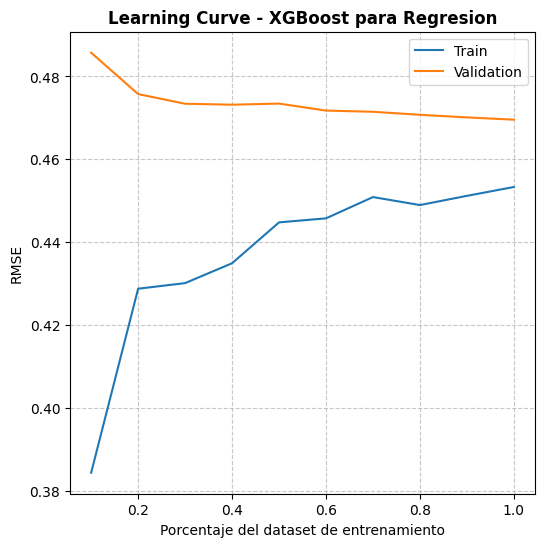

In [15]:
plot_learning_curves_xgboost_regression(X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, **mejores_parametros)

Analizamos las feature importance:

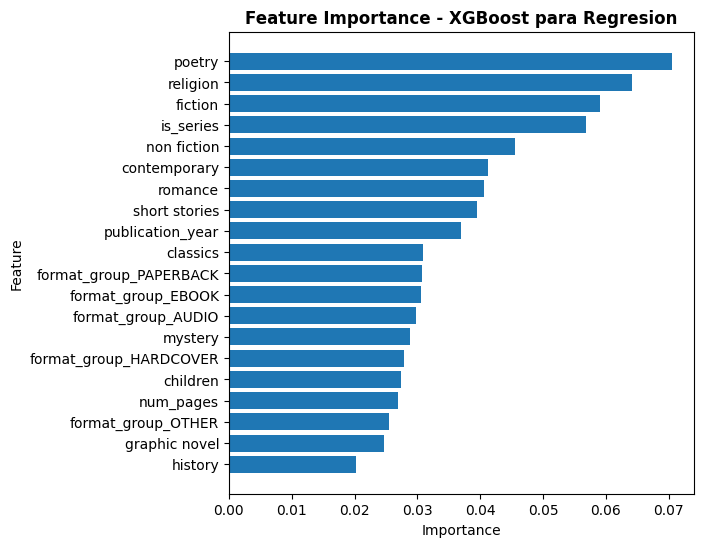

In [16]:
importancias_coef_xgb_reg = pd.DataFrame({"feature": features, "importance": modeloXGBoostRegresion.feature_importances_})
importancias_coef_xgb_reg = importancias_coef_xgb_reg.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_reg, "para Regresion")

## XGBoost con features basicas - Clasificacion

Hago un poco de rebalanceo antes de empezar, utilizo X_sub_undersampling (X_train con menos datos de la clase mayoritaria 4).

In [17]:
pesos = {0:12, 1:30, 2:7, 3:2, 4:1, 5:2}
pesos_transformados_sub = np.array([pesos[y] for y in y_sub_clasificacion_undersampling])
XGBoostGridSearchClasificacion = XGBClassifier(objective = "multi:softmax", num_class = 6, random_state = 42) 

#uso los mismos indices para obtener los subconjuntos
grid = GridSearchCV(estimator = XGBoostGridSearchClasificacion, param_grid = parametros_grid_search_xgb, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
grid.fit(X_sub_undersampling, y_sub_clasificacion_undersampling, sample_weight = pesos_transformados_sub)

mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor F1 CV: {grid.best_score_}")

Fitting 3 folds for each of 108 candidates, totalling 324 fits
Mejores parametros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 1.0}
Mejor F1 CV: 0.31754689833792443


              Train  Validation
Accuracy   0.651313    0.653927
Precision  0.407528    0.262215
Recall     0.442268    0.299225
F1         0.414621    0.271350


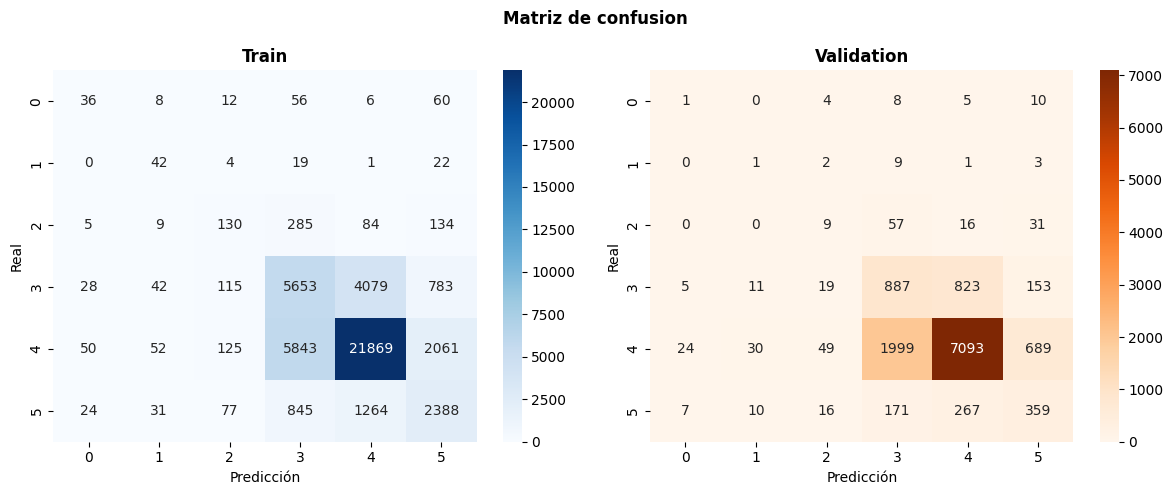

In [18]:
pesos_transformados_train = np.array([pesos[y] for y in y_train_undersampling])
modeloXGBoostClasificacion = XGBClassifier(**mejores_parametros, objective = "multi:softmax", num_class = 6, random_state = 42) 
modeloXGBoostClasificacion.fit(X_train_undersampling, y_train_undersampling, sample_weight = pesos_transformados_train) #XGBoost no requiere obligatoriamnete que se escalen los valores, pero lo hag para poder comprar la feature importance

y_pred_train_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_train_undersampling))
y_pred_val_modeloXGBoostClasificacion = (modeloXGBoostClasificacion.predict(X_val_scaled))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloXGBoostClasificacion, y_train_undersampling)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloXGBoostClasificacion, y_val_clasificacion)
tabla_metricas_xgboost_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_xgboost_clasificacion)

cm_train = confusion_matrix(y_train_undersampling, y_pred_train_modeloXGBoostClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloXGBoostClasificacion)
plot_confusion_matrix(cm_train, cm_val)

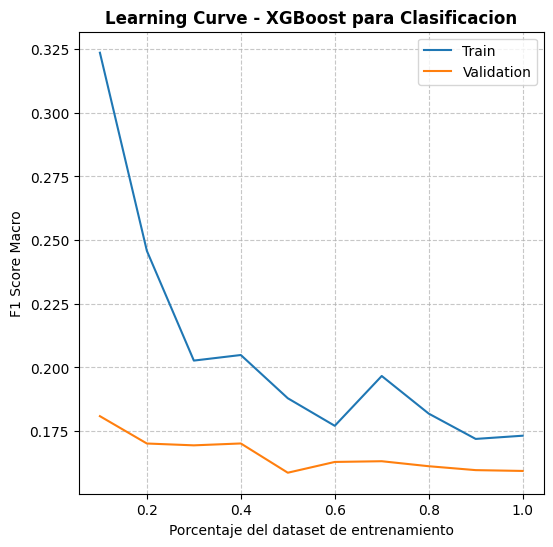

In [19]:
plot_learning_curves_xgboost_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, **mejores_parametros)

Analizamos las feature importance:

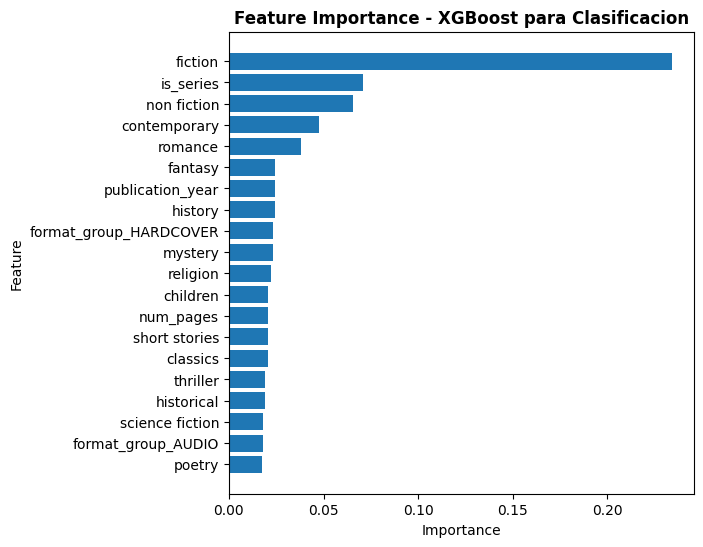

In [20]:
importancias_coef_xgb_clasf = pd.DataFrame({"feature": features, "importance": modeloXGBoostClasificacion.feature_importances_})
importancias_coef_xgb_clasf = importancias_coef_xgb_clasf.sort_values("importance", ascending = False)
plot_feature_importance_xgb(importancias_coef_xgb_clasf, "para Clasificacion")

## Random Forest con features basicas - Regresion

Grid Search: tomo una muestra de 100 mil datos para encontrar los mejores hiperparametros, una vez encontrados estos valores reentreno con todos los datos

In [ ]:
RandomForestGridSearchRegresion = RandomForestRegressor(random_state=42)
grid = GridSearchCV(estimator = RandomForestGridSearchRegresion, param_grid = parametros_grid_search_rf, cv = 3, scoring="r2", n_jobs=-1, verbose=2)
grid.fit(X_sub, y_sub_regresion)
mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor R² CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
Mejor R² CV: 0.11702738356955551


In [22]:
modeloRandomForestRegresion = RandomForestRegressor(**mejores_parametros, random_state = 42)
modeloRandomForestRegresion.fit(X_train_scaled, y_train_regresion)

y_pred_train_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_train_scaled)
y_pred_val_modeloRandomForestRegresion = modeloRandomForestRegresion.predict(X_val_scaled)

metricas_train = evaluar_metricas_regresion(y_pred_train_modeloRandomForestRegresion, y_train_regresion)
metricas_val = evaluar_metricas_regresion(y_pred_val_modeloRandomForestRegresion, y_val_regresion)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

         Train  Validation
MSE   0.185405    0.220928
RMSE  0.430587    0.470030
MAE   0.282392    0.319746
R²    0.259117    0.109163


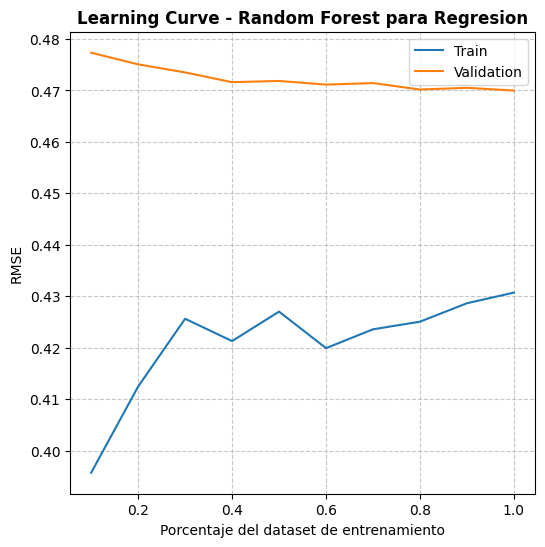

In [23]:
plot_learning_curves_randomforest_regression(X_train, y_train_regresion, X_val, y_val_regresion, **mejores_parametros)

Analizamos la feature importance:

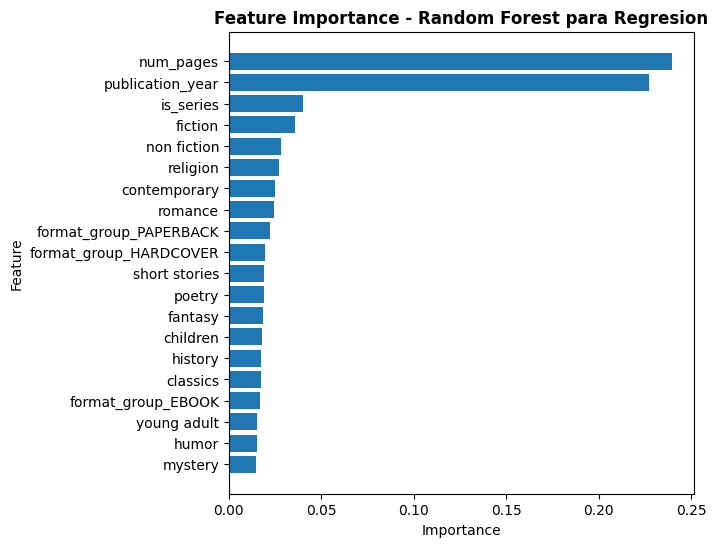

In [24]:
importancias_coef_rf_reg = pd.DataFrame({"feature": features, "importance": modeloRandomForestRegresion.feature_importances_})
importancias_coef_rf_reg = importancias_coef_rf_reg.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_reg, "para Regresion")

## Random Forest con features basicas - Clasificacion

Uso rebalanceo undersampling + cost re weight

In [25]:
pesos = {0:12, 1:30, 2:7, 3:2, 4:1, 5:2}
RandomForestGridSearchClasificacion = RandomForestClassifier(random_state = 42, class_weight = pesos)

#uso las mismas opciones de hiperparametros q use en regresion, y los mismos indices para obtener los subconjuntos
grid = GridSearchCV(estimator = RandomForestGridSearchClasificacion, param_grid = parametros_grid_search_rf, cv = 3, scoring = "f1_macro", n_jobs = -1, verbose = 2)
grid.fit(X_sub_undersampling, y_sub_clasificacion_undersampling)

mejores_parametros = grid.best_params_
print(f"Mejores parametros: {mejores_parametros}")
print(f"Mejor F1 CV: {grid.best_score_}")

Fitting 3 folds for each of 162 candidates, totalling 486 fits
Mejores parametros: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}
Mejor F1 CV: 0.29623819341674795


              Train  Validation
Accuracy   0.744604    0.679066
Precision  0.544718    0.261764
Recall     0.506949    0.272474
F1         0.507783    0.261124


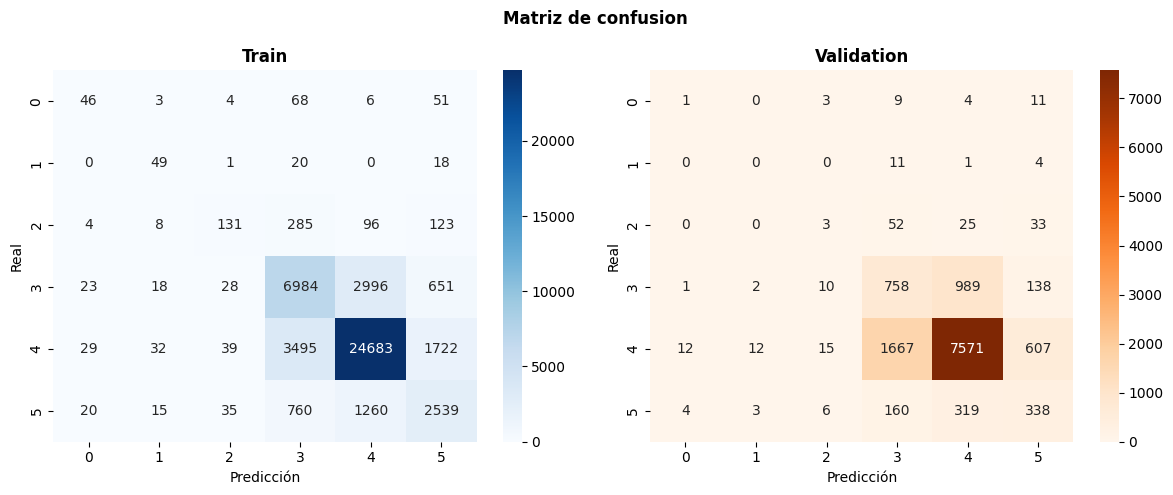

In [26]:
modeloRandomForestClasificacion = RandomForestClassifier(**mejores_parametros, random_state = 42, class_weight = pesos)
modeloRandomForestClasificacion.fit(X_train_undersampling, y_train_undersampling)

y_pred_train_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_train_undersampling))
y_pred_val_modeloRandomForestClasificacion = (modeloRandomForestClasificacion.predict(X_val_scaled))

metricas_train = evaluar_metricas_clasificacion(y_pred_train_modeloRandomForestClasificacion, y_train_undersampling)
metricas_val = evaluar_metricas_clasificacion(y_pred_val_modeloRandomForestClasificacion, y_val_clasificacion)
tabla_metricas_rf_clasificacion = tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1"])
print(tabla_metricas_rf_clasificacion)

cm_train = confusion_matrix(y_train_undersampling, y_pred_train_modeloRandomForestClasificacion)
cm_val = confusion_matrix(y_val_clasificacion, y_pred_val_modeloRandomForestClasificacion)
plot_confusion_matrix(cm_train, cm_val)

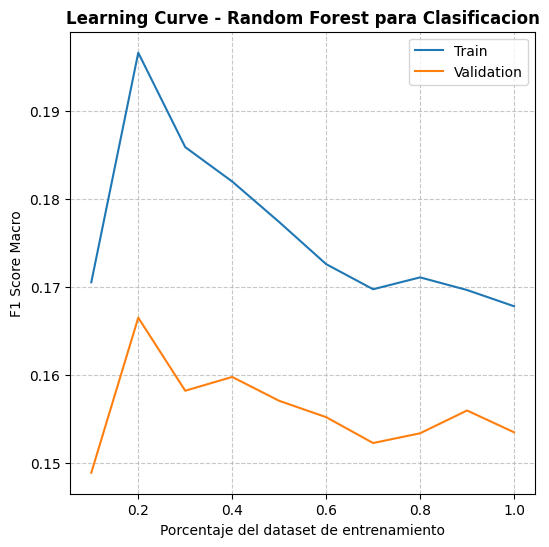

In [27]:
plot_learning_curves_randomforest_classification(X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, **mejores_parametros)

Analizamos la feature importance:

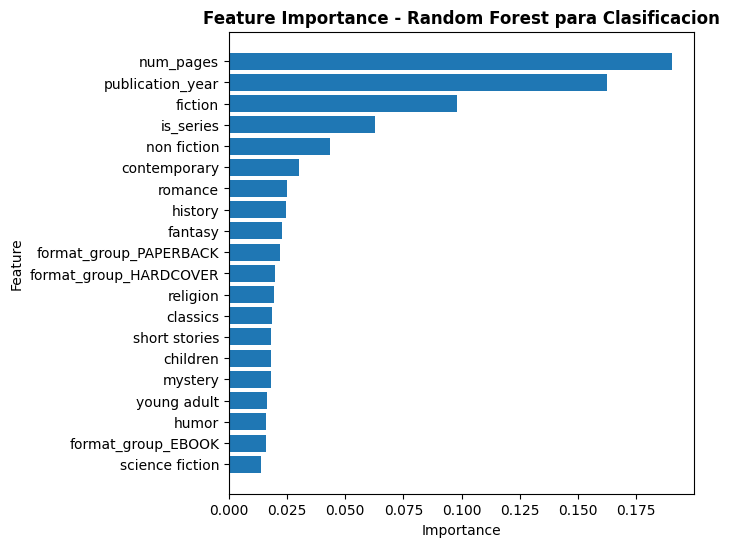

In [28]:
importancias_coef_rf_clasf = pd.DataFrame({"feature": features, "importance": modeloRandomForestClasificacion.feature_importances_})
importancias_coef_rf_clasf = importancias_coef_rf_clasf.sort_values("importance", ascending = False)
plot_feature_importance_rf(importancias_coef_rf_clasf, "para Clasificacion")

## Red neuronal con features basicas - Regresion

PyTorch: 100%|██████████| 100/100 [04:03<00:00,  2.43s/epoca, epoch=100]


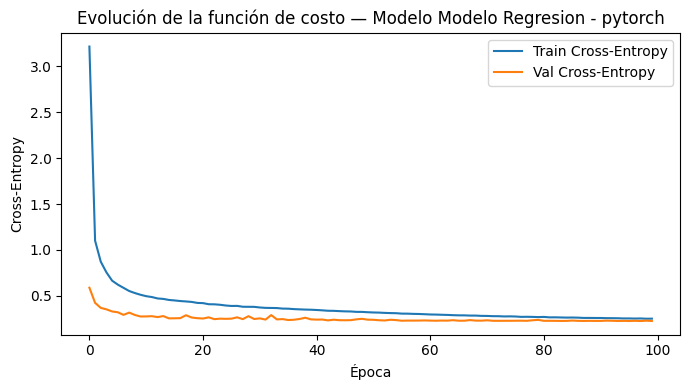

         Train  Validation
MSE   0.224237    0.225766
RMSE  0.473537    0.475148
MAE   0.319889    0.322131
R²    0.111304    0.095642


In [24]:
if torch.cuda.is_available():
  device = "cuda"
else:
  device = "cpu"

X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)

modelo_regresion = MLP_regresion(input_size = X_train_scaled.shape[1], hidden_layers = [128, 64], activation = nn.ReLU, dropout = 0.2).to(device)
metricas_train, metricas_val = run_experiment_pytorch_regresion(modelo_regresion, "Modelo Regresion", X_train_scaled, y_train_regresion, X_val_scaled, y_val_regresion, device)
print(tabla_metricas(metricas_train, metricas_val, ["MSE", "RMSE", "MAE", "R²"]))

Las redes neuronales con pytorch no tienen un atributo para acceder a la feature importance, a diferencia de XGBoost o Random Forest. Para simular esto, se agarra por separado cada feature y se la mezcla (de esta manera se descorrelaciona la salida del modelo con esta feature). Despues, se predice con esa nueva feature y se evalua la diferencia con el X original. A mayor diferencia mayor impacto tiene la feature. 

In [ ]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device,metric_fn=mean_squared_error, higher_is_better=False, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Regresión (PyTorch)")

## Red neuronal con features basicas - Clasificacion

PyTorch: 100%|██████████| 100/100 [03:03<00:00,  1.83s/epoca, epoch=100]


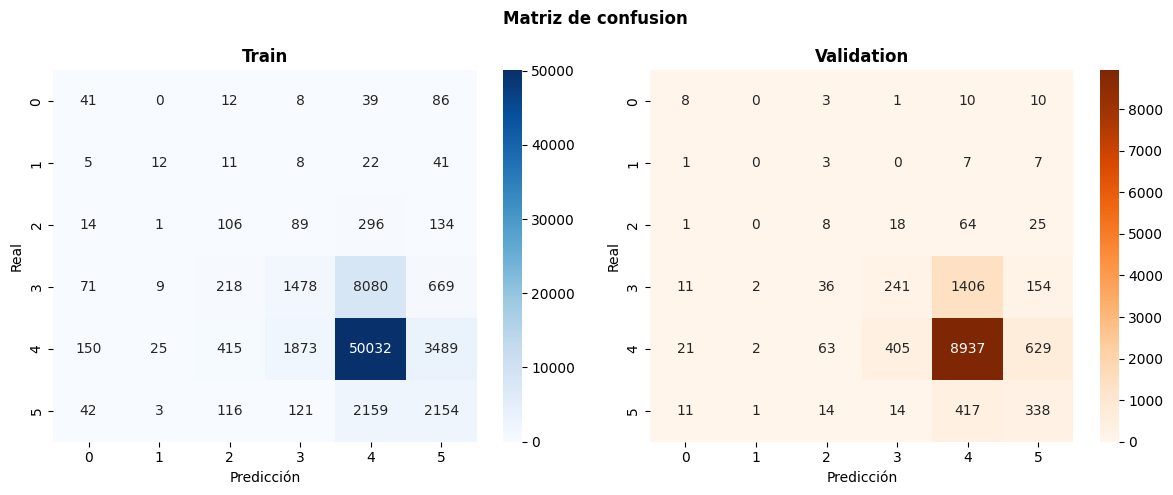

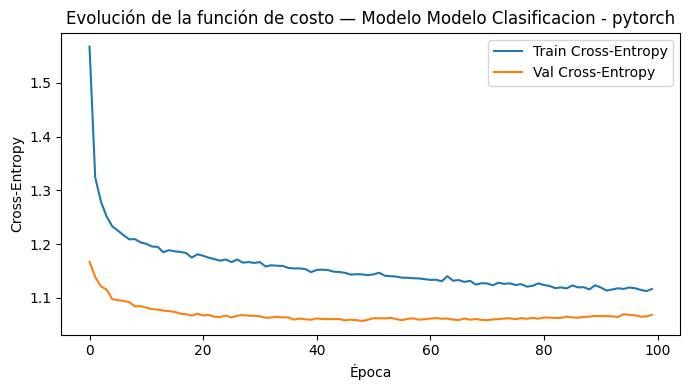

              Train  Validation
Accuracy   0.747241    0.740752
Precision  0.342299    0.280645
Recall     0.335025    0.293838
F1_score   0.319214    0.274203


In [23]:
#no termine de decidir si es mejor con undersampling + cost o solo con cost
X_train_scaled = X_train_scaled.astype(np.float32)
X_val_scaled = X_val_scaled.astype(np.float32)

modelo_clasificacion = MLP_clasificacion(input_size = X_train_scaled.shape[1], hidden_layers = [128, 64], n_classes = 6, activation = nn.ReLU, dropout = 0.2).to(device)
metricas_train, metricas_val = run_experiment_pytorch_clasificacion(modelo_clasificacion, "Modelo Clasificacion", X_train_scaled, y_train_clasificacion, X_val_scaled, y_val_clasificacion, device)
print(tabla_metricas(metricas_train, metricas_val, ["Accuracy", "Precision", "Recall", "F1_score"]))


In [ ]:
feature_importance_regresion = permutation_importance_pytorch(modelo_regresion, X_val_scaled, y_val_regresion, features, device, metric_fn=accuracy_score, higher_is_better=X_train_undersampling, n_repeats=10)
plot_feature_importance_pytorch(feature_importance_regresion, top_n=20, title="Feature Importance - Modelo Clasificacion (PyTorch)")

In [ ]:
#from sklearn.model_selection import ParameterGrid
#
#def grid_search_mlp(X_train, y_train, X_val, y_val, param_grid, device, epochs=30, waiting=3):
#    resultados = []
#    mejor_f1 = -1
#    mejor_config = None
#    mejor_modelo_state = None
#
#    for params in ParameterGrid(param_grid):
#        print(f"Probando: {params}")
#
#        modelo = MLP_clasificacion(
#            input_size=X_train.shape[1],
#            hidden_layers=params["hidden_layers"],
#            n_classes=6,
#            activation=nn.ReLU,
#            dropout=params["dropout"]
#        ).to(device)
#
#        counts = np.bincount(y_train)
#        weights = np.sqrt(counts.sum() / counts)
#        weights = weights / weights.mean()
#        class_weights = torch.tensor(weights, dtype=torch.float32, device=device)
#        loss_fn = nn.CrossEntropyLoss(weight=class_weights)
#        optimizer = torch.optim.Adam(modelo.parameters(), lr=params["lr"])
#
#        train_loader, val_loader = make_dataloaders(X_train, y_train, X_val, y_val, n_batches=64)
#        modelo.train_model(train_loader, val_loader, optimizer, loss_fn, device, epochs=epochs, waiting=waiting)
#
#        y_pred_val = modelo.predict(X_val, device)
#        f1_val = f1_score(y_val, y_pred_val, average="macro")
#        print(f"  -> f1_macro val: {f1_val:.4f}")
#
#        resultados.append({**params, "f1_macro_val": f1_val})
#
#        if f1_val > mejor_f1:
#            mejor_f1 = f1_val
#            mejor_config = params
#            mejor_modelo_state = copy.deepcopy(modelo.state_dict())
#
#    print(f"\nMejores parametros: {mejor_config}")
#    print(f"Mejor F1 macro val: {mejor_f1:.4f}")
#    return mejor_config, mejor_f1, resultados, mejor_modelo_state